# Local diabatic dynamics with PySCF: LiH hopping comparison

Run the ordinary **`MeanField`** and **`FewestSwitchesSurfaceHopping`** algorithms using
`LocalDiabaticAbInitio`, and compare them with their **ab initio counterparts**.
The default CASSCF calculation matches the [CASSCF notebook](pyscf_casscf_examples.ipynb):
**0 K Wigner sampling, pure S1, the same stretch impulse, seeds 0–99,
100 trajectories, and 100 atomic time units of propagation**.

FSSH uses the same 1 a.u. update and collection interval as that notebook. Mean field
uses a smaller 0.1 a.u. update to control ordinary RK4 electronic-normalization error,
with the same total duration and 1 a.u. collection grid. Every comparison pair uses
the same nuclear samples, electronic preparation, energy offset, and seeds.

We compare **instantaneous adiabatic populations**, `dm_adb`, and retain individual
FSSH active-surface histories to identify accepted hops. The local computational
frame is transported separately along every trajectory; its raw populations are
not a shared ensemble observable. CMS-PDFT and restricted TDA remain selectable.

## 1. Environment

From the repository root, install into the environment selected as this notebook's kernel:

```bash
python -m pip install -e '.[pyscf]' matplotlib ipykernel
```

PySCF 2.14.x is required. Q-Chem and ASE are not needed. Run the notebook from top to
bottom after changing the settings. The default runs the full 100-trajectory comparison and can take substantial time,
especially for the local RK4 force stages. For a quick check, temporarily reduce
`num_trajs` and `batch_size` together; `seeds=np.array([13])` selects the original
hopping demonstration trajectory. Restore the defaults for ensemble comparisons.

In [1]:
import os
import copy
import warnings
from functools import partial
from time import perf_counter

for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")

import numpy as np
import matplotlib.pyplot as plt
import pyscf
from qclab import Simulation, ingredients
from qclab.algorithms import (
    MeanField, MeanFieldAbInitio,
    FewestSwitchesSurfaceHopping, FewestSwitchesSurfaceHoppingAbInitio,
)
from qclab.dynamics import serial_driver
from qclab.functions import z_to_q, z_to_p, qp_to_z
from qclab.interfaces import QCLabPySCFInterface
from qclab.models import AbInitio, LocalDiabaticAbInitio
from qclab.numerical_constants import (
    AMU_TO_EMASS, ANGSTROM_TO_BOHR, AU_TIME_TO_FS,
    HA_TO_EV, INVCM_TO_HA, K_B_HA_PER_K,
)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
warnings.filterwarnings("ignore", message="OpenMP is not available.*",
                        category=UserWarning, module=r"pyscf\.lib\.misc")
print("PySCF:", pyscf.__version__)

PySCF: 2.14.0


## 2. Choose the electronic method and run length

- `method="casscf"`: two singlet SA-CASSCF states.
- `method="cms-pdft"`: two singlet CMS-PDFT states; choose `tPBE`, `tBLYP`, or `ftPBE`.
- `method="tddft"`: restricted **TDA**, with `pbe` or `b3lyp` and singlet or triplet
  excitations. We select response roots `[0, 3]`, giving `[S0, S1, S4]` or
  `[S0, T1, T4]`, avoiding LiH's degenerate Π pair.

TDA uses **`use_etfs=False`** so analytic couplings and wavefunction overlaps use
matching basis-motion conventions. Full TDDFT is not part of this example.

All inputs use atomic units: Bohr, electron masses, Hartree, and atomic time.
The shared `energy_offset=-7.8` removes a common electronic phase and improves
ordinary mean-field RK4 accuracy without changing forces or energy gaps.

For CASSCF, the molecular inputs and electronic convergence settings also match the
reference notebook. The finer mean-field update is explicit below; FSSH retains the
reference timestep.

In [8]:
method = "casscf"                  # "casscf", "cms-pdft", or "tddft" (TDA).
otxc = "tPBE"                     # CMS: "tPBE", "tBLYP", "ftPBE".
xc = "pbe"                        # TDA: "pbe", "b3lyp".
excited_multiplicity = 1           # TDA: 1 (singlets) or 3 (triplets).

initialization = "wigner"          # "fixed" or "wigner".
electronic_preparation = "excited"  # "superposition" or "excited".
initial_electronic_state = 1       # Zero-based: S1 (T1 for triplet TDA).
temperature_K = 0.0                # Used only by Wigner sampling; Kelvin.
stretch_velocity_kick = 0.03       # Wigner impulse; relative velocity in Bohr/a.u.

settings = {
    "num_trajs": 1,
    "batch_size": 1,
    "tmax": 100.0,
    "dt_update": 1.0,
    "dt_collect": 1.0,
    "progress_bar": True,
}
seeds = np.array([13])#np.arange(settings["num_trajs"], dtype=int)
mean_field_dt_update = 0.1  # Smaller RK4 step; same duration and collected times.
energy_offset = -7.8

assert method in {"casscf", "cms-pdft", "tddft"}
assert otxc in {"tPBE", "tBLYP", "ftPBE"}
assert xc in {"pbe", "b3lyp"} and excited_multiplicity in {1, 3}
assert initialization in {"fixed", "wigner"}
assert electronic_preparation in {"superposition", "excited"}
assert np.isfinite(temperature_K) and temperature_K >= 0
assert len(seeds) == settings["num_trajs"]
print("Duration: %.3f fs (%g a.u.); trajectories: %d" % (
    settings["tmax"] * AU_TIME_TO_FS, settings["tmax"], len(seeds)))
print("FSSH dt: %g a.u.; mean-field dt: %g a.u.; collection interval: %g a.u." % (
    settings["dt_update"], mean_field_dt_update, settings["dt_collect"]))
print("Trajectory seeds:", seeds)

Duration: 2.419 fs (100 a.u.); trajectories: 1
FSSH dt: 1 a.u.; mean-field dt: 0.1 a.u.; collection interval: 1 a.u.
Trajectory seeds: [13]


In [9]:
atom_names = ["Li", "H"]
atom_positions = np.array([[0., 0., 0.], [0., 0., 3.]])
atom_masses = np.array([7.0160034366, 1.00782503223]) * AMU_TO_EMASS

calculator_args = {
    "method_es": method, "basis": "sto-3g", "charge": 0, "multiplicity": 1,
    "num_threads": 1, "max_memory": 1000,
    "scf_options": {"conv_tol": 1e-12},
}
if method == "tddft":
    num_quantum_states = 3
    state_labels = ["S0", "S1", "S4"] if excited_multiplicity == 1 else ["S0", "T1", "T4"]
    calculator_args.update({
        "tda": True, "xc": xc, "excited_multiplicity": excited_multiplicity,
        "excited_state_indices": [0, 3], "use_etfs": False,
        "grids_level": 5, "td_options": {"conv_tol": 1e-11},
    })
else:
    num_quantum_states = 2
    state_labels = ["S0", "S1"]
    calculator_args.update({
        "ncas": 2, "nelecas": 2,
        "casscf_options": {"conv_tol": 1e-11, "conv_tol_grad": 1e-8,
                           "ah_conv_tol": 1e-14, "max_cycle_macro": 200},
    })
    if method == "cms-pdft":
        calculator_args.update({
            "otxc": otxc, "grids_level": 5,
            "cms_options": {"conv_tol_diabatize": 1e-10},
            "response_options": {"conv_atol": 1e-10, "conv_rtol": 0., "max_cycle": 200},
        })

if method == "casscf":
    calculator_args["scf_options"] = {"conv_tol": 1e-10}
    calculator_args["casscf_options"] = {
        "conv_tol": 1e-9, "conv_tol_grad": 1e-6, "ah_conv_tol": 1e-14,
    }

wf_initial = np.zeros(num_quantum_states, dtype=complex)
if electronic_preparation == "excited":
    wf_initial[initial_electronic_state] = 1.0
elif num_quantum_states == 2:
    wf_initial[:] = 1.0 / np.sqrt(2)
else:
    # A same-spin excited-state superposition exercises the selected S1/S4 or T1/T4 coupling.
    wf_initial[1:] = 1.0 / np.sqrt(2)
np.testing.assert_allclose(np.vdot(wf_initial, wf_initial), 1.0)
print("States:", state_labels, "Initial coefficients:", wf_initial)

States: ['S0', 'S1'] Initial coefficients: [0.+0.j 1.+0.j]


## 3. Match the 0 K kicked Wigner samples

The default computes one set of S0 mass-weighted modes with exactly the same
SA-CASSCF(2,2) model, convergence tolerances, displacement, and mode sign as the
CASSCF notebook. The same seeds therefore produce the same initial positions
and momenta, before either representation is propagated.

Sampling follows \(q=q_0+M^{-1/2}UQ\), \(p=M^{1/2}UP\), followed by the same
center-of-mass-preserving relative stretch-velocity impulse of **0.03 Bohr/a.u.**
At **0 K**, the zero-point position and momentum widths remain nonzero.

Both runs start in **S1**. For optional triplet TDA, selected state 1 is T1.
The alternative `initialization="fixed"` and `electronic_preparation="superposition"`
remain available for force diagnostics, but are not the default hopping comparison.

In [10]:
vibrations = {}
if initialization == "wigner":
    sampling_calculator_args = {
        "method_es": "casscf", "basis": "sto-3g", "charge": 0, "multiplicity": 1,
        "ncas": 2, "nelecas": 2, "num_threads": 1, "max_memory": 1000,
        "scf_options": {"conv_tol": 1e-10},
        "casscf_options": {"conv_tol": 1e-9, "conv_tol_grad": 1e-6, "ah_conv_tol": 1e-14},
    }
    sampling_calculator = QCLabPySCFInterface(
        atom_positions=atom_positions, atom_masses=atom_masses, atom_names=atom_names,
        num_quantum_states=2, **sampling_calculator_args,
    )
    vibrations = sampling_calculator.normal_modes(state_ind=0, delta=1e-3)
    if vibrations["normal_mode"][5, 0] < 0:
        vibrations["normal_mode"] *= -1
    modes = vibrations["normal_mode"]
    frequencies = vibrations["harmonic_frequency"]
    assert vibrations["normal_mode_convention"] == "mass_weighted"
    assert frequencies.shape == (1,) and modes.shape == (6, 1)
    assert np.isrealobj(frequencies) and np.all(np.isfinite(frequencies)) and np.all(frequencies > 0)
    np.testing.assert_allclose(modes.T @ modes, np.eye(1), atol=1e-8)
    print("Shared CASSCF sampling frequency (cm^-1):", frequencies / INVCM_TO_HA)
else:
    print("Fixed positions and momenta: no normal-mode calculation required.")

model_constants = {
    "calculator": "pyscf", "calculator_args": calculator_args,
    "atom_names": atom_names, "atom_positions": atom_positions, "atom_masses": atom_masses,
    "num_quantum_states": num_quantum_states, "energy_offset": energy_offset,
    "kBT": temperature_K * K_B_HA_PER_K,
    **vibrations,
}

if initialization == "fixed":
    model_constants["init_momentum"] = np.array([0., 0., -1., 0., 0., 1.])


def init_kicked_wigner(model, parameters, **kwargs):
    """Sample the shared Wigner distribution, then add opposite stretch impulses."""
    z = AbInitio.init_classical(model, parameters, **kwargs)
    mass = model.constants.classical_coordinate_mass
    weight = model.constants.classical_coordinate_weight
    q = z_to_q(z, mass, weight).reshape((-1, 2, 3))
    p = z_to_p(z, mass, weight).reshape((-1, 2, 3))
    bond = q[:, 1] - q[:, 0]
    direction = bond / np.linalg.norm(bond, axis=1)[:, None]
    reduced_mass = np.prod(model.constants.atom_masses) / np.sum(model.constants.atom_masses)
    impulse = reduced_mass * stretch_velocity_kick * direction
    p[:, 0] -= impulse
    p[:, 1] += impulse
    return qp_to_z(q.reshape((-1, 6)), p.reshape((-1, 6)), mass, weight)


initial_condition_ingredient = (init_kicked_wigner if initialization == "wigner" else
                                ingredients.init_classical_definite_position_momentum)
# Verify the entire batch of starting samples is identical before either propagation.
preview_samples = []
for model_class in (LocalDiabaticAbInitio, AbInitio):
    preview_model = model_class(copy.deepcopy(model_constants))
    preview_samples.append(initial_condition_ingredient(preview_model, {}, seed=seeds.copy()))
np.testing.assert_array_equal(preview_samples[0], preview_samples[1])
q0 = z_to_q(preview_samples[0], preview_model.constants.classical_coordinate_mass,
             preview_model.constants.classical_coordinate_weight).reshape((-1, 2, 3))
p0 = z_to_p(preview_samples[0], preview_model.constants.classical_coordinate_mass,
             preview_model.constants.classical_coordinate_weight).reshape((-1, 2, 3))
np.testing.assert_allclose(p0.sum(axis=1), 0., atol=1e-10)
print("Initial bond lengths (Bohr):", np.linalg.norm(q0[:, 1] - q0[:, 0], axis=1))
print("Identical nuclear samples confirmed for both representations.")
print("Sampling temperature: %.1f K; relative stretch kick: %.3f Bohr/a.u." % (
    temperature_K, stretch_velocity_kick))

Shared CASSCF sampling frequency (cm^-1): [1669.70061343]
Initial bond lengths (Bohr): [2.85590431]
Identical nuclear samples confirmed for both representations.
Sampling temperature: 0.0 K; relative stretch kick: 0.030 Bohr/a.u.


## 4. Build fresh matched simulations

At initialization the local computational basis equals the initial adiabatic basis.
Set **`wf_db` for the ordinary algorithms**, and **`wf_adb` for the ab initio algorithms**
to prepare matching states. Each run receives its own model, solver cache, and algorithm.

Both formulations collect `dm_adb`. We also record the bond length and electronic
normalization error without changing the dynamics. The local adapter supplies the
full Hamiltonian-gradient operator; no extra derivative-coupling force is added.

In [11]:
def update_diagnostics(sim, state, parameters, wf_name="wf_db", z_name="z",
                       bond_name="bond_length", norm_name="electronic_norm_error"):
    z = state[z_name]
    c = state[wf_name]
    if not np.all(np.isfinite(z)) or not np.all(np.isfinite(c)):
        raise RuntimeError("Nonfinite nuclear coordinates or electronic coefficients.")
    q = z_to_q(z, sim.model.constants.classical_coordinate_mass,
                 sim.model.constants.classical_coordinate_weight).reshape((-1, 2, 3))
    state[bond_name] = np.linalg.norm(q[:, 1] - q[:, 0], axis=1)
    norm_error = np.abs(np.sum(np.abs(c)**2, axis=-1) - 1.)
    if np.any(norm_error > 1e-6):
        raise RuntimeError("Electronic normalization drift exceeded 1e-6; reduce the propagation time step.")
    state[norm_name] = norm_error
    return state, parameters


def collect_diagnostics(sim, state, parameters, bond_name="bond_length",
                        norm_name="electronic_norm_error", bond_output_name="bond_length",
                        norm_output_name="electronic_norm_error"):
    state["output_dict"][bond_output_name] = state[bond_name].copy()
    state["output_dict"][norm_output_name] = state[norm_name].copy()
    return state, parameters


algorithm_pairs = {
    "Mean field": (MeanField, MeanFieldAbInitio),
    "FSSH": (FewestSwitchesSurfaceHopping, FewestSwitchesSurfaceHoppingAbInitio),
}


def make_simulation(algorithm_name, representation, run_settings=None):
    local = representation == "Local diabatic"
    if representation not in {"Local diabatic", "Ab initio"}:
        raise ValueError("Unknown representation")
    simulation_settings = copy.deepcopy(settings if run_settings is None else run_settings)
    if algorithm_name == "Mean field" and run_settings is None:
        simulation_settings["dt_update"] = mean_field_dt_update
    sim = Simulation(simulation_settings)
    sim.model = (LocalDiabaticAbInitio if local else AbInitio)(copy.deepcopy(model_constants))
    sim.model.ingredients = sim.model.ingredients + [("init_classical", initial_condition_ingredient)]
    algorithm_class = algorithm_pairs[algorithm_name][0 if local else 1]
    sim.algorithm = (algorithm_class() if local else
                     algorithm_class({"use_wf_overlaps_for_adb_connection": True}))
    wf_name = "wf_db" if local else "wf_adb"
    sim.initial_state[wf_name] = wf_initial.copy()
    sim.algorithm.collect_recipe = sim.algorithm.collect_recipe + [
        partial(update_diagnostics, wf_name=wf_name), collect_diagnostics,
    ]
    return sim

## 5. Run mean-field dynamics

Both representations start in pure S1 with the shared kicked Wigner samples and
propagate for 100 a.u. by default. The mean-field update is 0.1 a.u. to control
RK4 normalization error as the bond stretches; results are collected every 1 a.u.
The algorithms use different integrators, so compare their timestep-converged
observables rather than requiring identical finite-step paths.

In [12]:
results = {}
for representation in ("Ab initio","Local diabatic"):
    start = perf_counter()
    results["Mean field", representation] = serial_driver(
        make_simulation("Mean field", representation), seeds=seeds.copy())
    print("Mean field / %s: %.2f s" % (representation, perf_counter() - start))

100%|██████████| 1001/1001 [01:41<00:00,  9.87it/s]


Mean field / Ab initio: 101.37 s


100%|██████████| 1001/1001 [06:40<00:00,  2.50it/s]

Mean field / Local diabatic: 400.67 s


## 6. Run fewest-switches surface hopping and retain the active surfaces

Both FSSH formulations use the CASSCF notebook's **100 a.u. duration and 1 a.u.
update/collection interval**. They hop between **adiabatic eigenstates** and start
on S1. Identical seeds match their random-number sequences, while finite-step
integration differences can change individual stochastic hop times.

The collector keeps per-seed active surfaces and coordinates for the hopping plots
below. Changes in active-surface index identify accepted hops; frustrated hop
attempts do not change the active surface.

In [13]:
fssh_histories = {representation: [] for representation in ("Local diabatic", "Ab initio")}


def collect_surface_history(sim, state, parameters, *, history, seed_name="seed",
                            time_name="t", surface_name="act_surf_ind", z_name="z"):
    """Retain independent per-trajectory copies without changing the propagation."""
    history.append({
        "seed": state[seed_name].copy(), "time": state[time_name].copy(),
        "surface": state[surface_name].copy(), "z": state[z_name].copy(),
    })
    return state, parameters


for representation in ("Local diabatic", "Ab initio"):
    start = perf_counter()
    sim = make_simulation("FSSH", representation)
    sim.algorithm.collect_recipe = sim.algorithm.collect_recipe + [
        partial(collect_surface_history, history=fssh_histories[representation]),
    ]
    results["FSSH", representation] = serial_driver(sim, seeds=seeds.copy())
    print("FSSH / %s: %.2f s" % (representation, perf_counter() - start))

100%|██████████| 101/101 [00:40<00:00,  2.47it/s]


FSSH / Local diabatic: 40.90 s


100%|██████████| 101/101 [00:05<00:00, 19.03it/s]

FSSH / Ab initio: 5.31 s


## 7. Compare adiabatic populations

The mean-field diagonals are electronic populations. The stochastic FSSH diagonals
are **active-surface fractions** across the 100 trajectories by default.
The figures compare representations within each algorithm; the two algorithms need
not predict the same populations. The right panels resolve their numerical differences.

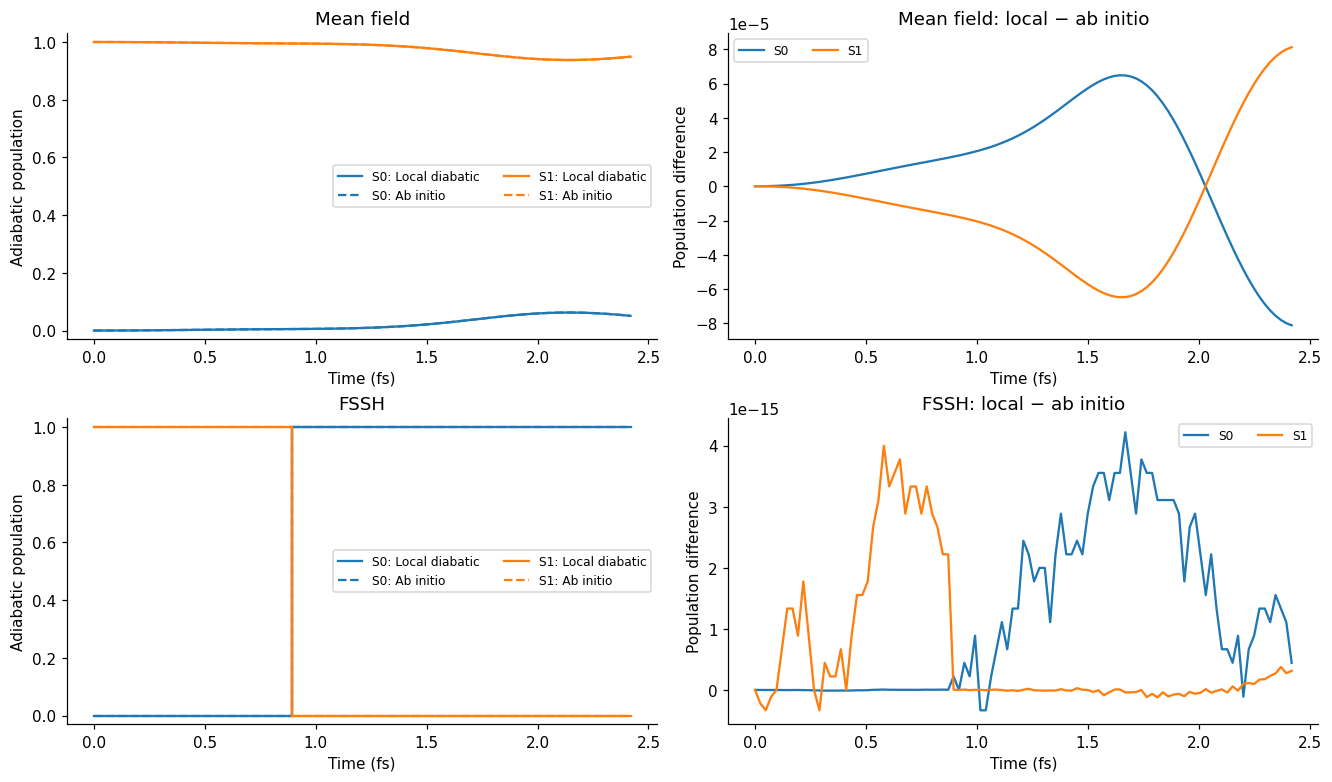

In [14]:
def populations(data):
    return np.diagonal(np.asarray(data.data_dict["dm_adb"]), axis1=-2, axis2=-1).real


fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for row, algorithm_name in enumerate(algorithm_pairs):
    local = results[algorithm_name, "Local diabatic"]
    reference = results[algorithm_name, "Ab initio"]
    time_fs = np.asarray(local.data_dict["t"]) * AU_TIME_TO_FS
    np.testing.assert_allclose(local.data_dict["t"], reference.data_dict["t"])
    for index, label in enumerate(state_labels):
        for representation, data, style in (
            ("Local diabatic", local, "-"), ("Ab initio", reference, "--"),
        ):
            axes[row, 0].plot(time_fs, populations(data)[:, index], style,
                              color="C%d" % index, label="%s: %s" % (label, representation),
                              drawstyle="steps-post" if algorithm_name == "FSSH" else "default")
        axes[row, 1].plot(time_fs, populations(local)[:, index] - populations(reference)[:, index],
                          color="C%d" % index, label=label)
    axes[row, 0].set(title=algorithm_name, ylabel="Adiabatic population", ylim=(-0.03, 1.03))
    axes[row, 1].set(title=algorithm_name + ": local − ab initio", ylabel="Population difference")
    axes[row, 1].ticklabel_format(axis="y", style="sci", scilimits=(-2, 2), useOffset=False)
    for axis in axes[row]:
        axis.set_xlabel("Time (fs)")
        axis.legend(fontsize=8, ncol=2)
plt.show()

### Accepted hops and the original demonstration trajectory

The first plot shows the fraction of trajectories that have completed at least one
accepted hop by each time. The second overlays the active surface of **seed 13**,
the hopping trajectory highlighted in the CASSCF notebook (when that seed is present).
These are stochastic trajectory observables, separate from mean-field populations.
The original CASSCF demonstration contains an S1-to-S0 hop for seed 13; we report
what each representation actually produces without forcing the histories to match.

Local diabatic: 1 accepted hops in 1 / 1 trajectories
  Seed 13: S1 -> S0 at 0.895 fs; Li–H 2.123 Angstrom
Ab initio: 1 accepted hops in 1 / 1 trajectories
  Seed 13: S1 -> S0 at 0.895 fs; Li–H 2.123 Angstrom


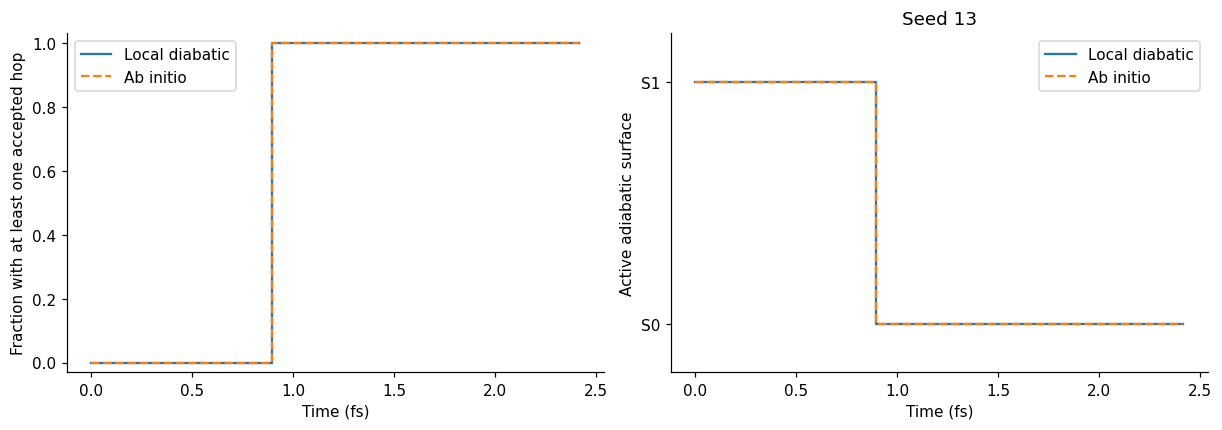

In [15]:
surface_histories = {}
hop_events = {}
for representation, frames in fssh_histories.items():
    by_seed = {}
    for frame in frames:
        for seed, time, surface, z in zip(frame["seed"], frame["time"], frame["surface"], frame["z"]):
            by_seed.setdefault(int(seed), []).append((float(time), int(surface), z.copy()))
    assert set(by_seed) == set(map(int, seeds))
    events = []
    for seed, rows in by_seed.items():
        rows.sort(key=lambda row: row[0])
        surfaces = np.array([row[1] for row in rows])
        for index in np.flatnonzero(np.diff(surfaces) != 0) + 1:
            q = z_to_q(rows[index][2], preview_model.constants.classical_coordinate_mass,
                         preview_model.constants.classical_coordinate_weight).reshape((2, 3))
            events.append({"seed": seed, "time_fs": rows[index][0] * AU_TIME_TO_FS,
                           "source": surfaces[index - 1], "destination": surfaces[index],
                           "bond_angstrom": np.linalg.norm(q[1] - q[0]) / ANGSTROM_TO_BOHR})
    surface_histories[representation] = by_seed
    hop_events[representation] = sorted(events, key=lambda event: event["time_fs"])
    print("%s: %d accepted hops in %d / %d trajectories" % (
        representation, len(events), len({event["seed"] for event in events}), len(seeds)))
    for event in hop_events[representation][:20]:
        print("  Seed %d: %s -> %s at %.3f fs; Li–H %.3f Angstrom" % (
            event["seed"], state_labels[event["source"]], state_labels[event["destination"]],
            event["time_fs"], event["bond_angstrom"]))
    if len(events) > 20:
        print("  ... all events are retained in hop_events[%r]." % representation)

selected_seed = 13 if 13 in seeds else int(seeds[0])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for representation, style in (("Local diabatic", "-"), ("Ab initio", "--")):
    time_fs = np.asarray(results["FSSH", representation].data_dict["t"]) * AU_TIME_TO_FS
    first_hops = {}
    for event in hop_events[representation]:
        first_hops.setdefault(event["seed"], event["time_fs"])
    first_times = np.sort(list(first_hops.values()))
    hopped_fraction = np.searchsorted(first_times, time_fs, side="right") / len(seeds)
    axes[0].step(time_fs, hopped_fraction, style, where="post", label=representation)
    rows = surface_histories[representation][selected_seed]
    axes[1].step(np.array([row[0] for row in rows]) * AU_TIME_TO_FS,
                 [row[1] for row in rows], style, where="post", label=representation)
axes[0].set(xlabel="Time (fs)", ylabel="Fraction with at least one accepted hop", ylim=(-0.03, 1.03))
axes[1].set(xlabel="Time (fs)", ylabel="Active adiabatic surface", title="Seed %d" % selected_seed,
            yticks=np.arange(num_quantum_states), yticklabels=state_labels,
            ylim=(-0.2, num_quantum_states - 0.8))
for axis in axes:
    axis.legend()
plt.show()

## 8. Check nuclear motion, energy drift, and normalization

Use the energy offset consistently in both runs. The printed initial total energy
has the common offset restored; the plotted drift is independent of that constant.
Normalization is monitored without renormalizing the propagated amplitudes.
Reduce `mean_field_dt_update` for mean field, or `settings["dt_update"]` for FSSH,
if normalization error or energy drift is too large.

Mean field / Local diabatic   norm error 3.77e-11; max |energy drift| 3.70e-03 eV; initial energy -6.94251143 Ha
Mean field / Ab initio        norm error 4.09e-14; max |energy drift| 6.76e-04 eV; initial energy -6.94251143 Ha
  Maximum |density-matrix difference|: 0.0006
FSSH / Local diabatic         norm error 3.22e-15; max |energy drift| 1.39e-02 eV; initial energy -6.94251143 Ha
FSSH / Ab initio              norm error 1.22e-14; max |energy drift| 1.75e-02 eV; initial energy -6.94251143 Ha
  Maximum |density-matrix difference|: 0.00603


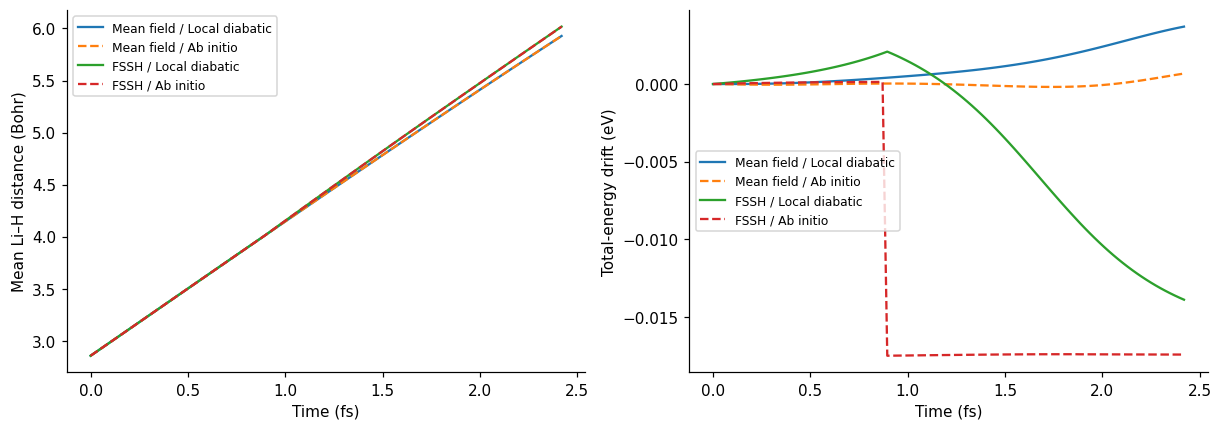

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for algorithm_name in algorithm_pairs:
    for representation, style in (("Local diabatic", "-"), ("Ab initio", "--")):
        data = results[algorithm_name, representation].data_dict
        time_fs = np.asarray(data["t"]) * AU_TIME_TO_FS
        total_energy = np.real(np.asarray(data["quantum_energy"]) + np.asarray(data["classical_energy"]))
        density = np.asarray(data["dm_adb"])
        for value in data.values():
            assert np.all(np.isfinite(value))
        np.testing.assert_allclose(np.trace(density, axis1=-2, axis2=-1), 1., atol=1e-6, rtol=0)
        np.testing.assert_allclose(density, density.conj().swapaxes(-1, -2), atol=1e-10)
        assert np.max(data["electronic_norm_error"]) < 1e-6
        label = algorithm_name + " / " + representation
        axes[0].plot(time_fs, data["bond_length"], style, label=label)
        axes[1].plot(time_fs, (total_energy - total_energy[0]) * HA_TO_EV, style, label=label)
        print("%-29s norm error %.2e; max |energy drift| %.2e eV; initial energy %.8f Ha" % (
            label, np.max(data["electronic_norm_error"]),
            np.max(np.abs(total_energy - total_energy[0])) * HA_TO_EV,
            total_energy[0] + energy_offset))
    local = results[algorithm_name, "Local diabatic"].data_dict
    reference = results[algorithm_name, "Ab initio"].data_dict
    np.testing.assert_allclose(local["bond_length"][0], reference["bond_length"][0], atol=1e-12)
    np.testing.assert_allclose(local["dm_adb"][0], reference["dm_adb"][0], atol=1e-12)
    print("  Maximum |density-matrix difference|: %.3g" % np.max(np.abs(local["dm_adb"] - reference["dm_adb"])))
axes[0].set(xlabel="Time (fs)", ylabel="Mean Li–H distance (Bohr)")
axes[1].set(xlabel="Time (fs)", ylabel="Total-energy drift (eV)")
for axis in axes:
    axis.legend(fontsize=8)
plt.show()

## 9. Optional timestep refinement

This is expensive for the full ensemble. Enable the next cell to compare mean-field trajectories over the **same physical
duration** using three successive timestep halvings. This adds eight simulations.
Use the same nuclear seeds and common collection grid at every resolution.

For FSSH, compare hopping probabilities and ensemble populations under refinement;
an individual stochastic history need not stay identical. The default notebook is
an interface demonstration, not a converged ensemble calculation.

100%|██████████| 1001/1001 [01:38<00:00, 10.12it/s]


dt = 0.10000 a.u.; final density difference = 5.681e-04


100%|██████████| 2001/2001 [03:20<00:00,  9.96it/s]


dt = 0.05000 a.u.; final density difference = 2.840e-04


100%|██████████| 4001/4001 [06:22<00:00, 10.46it/s]


dt = 0.02500 a.u.; final density difference = 1.420e-04


100%|██████████| 8001/8001 [12:35<00:00, 10.60it/s]


dt = 0.01250 a.u.; final density difference = 7.101e-05


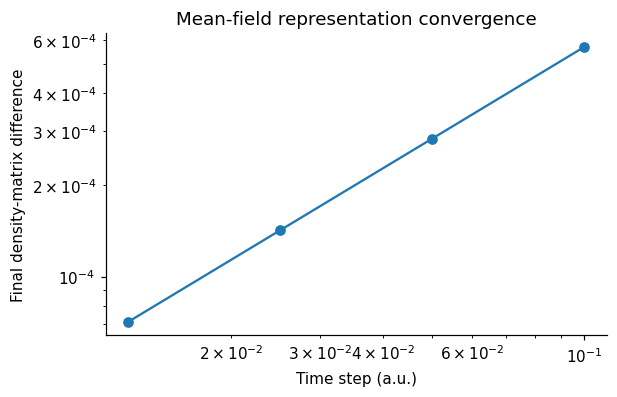

In [18]:
run_timestep_refinement = True
if run_timestep_refinement:
    step_sizes = mean_field_dt_update / (2. ** np.arange(4))
    errors = []
    for dt in step_sizes:
        refined_settings = copy.deepcopy(settings)
        refined_settings["dt_update"] = float(dt)
        pair = [serial_driver(make_simulation("Mean field", representation, refined_settings),
                              seeds=seeds.copy())
                for representation in ("Local diabatic", "Ab initio")]
        error = np.max(np.abs(pair[0].data_dict["dm_adb"][-1] - pair[1].data_dict["dm_adb"][-1]))
        errors.append(error)
        print("dt = %.5f a.u.; final density difference = %.3e" % (dt, error))
    fig, ax = plt.subplots(figsize=(5.5, 3.5), constrained_layout=True)
    ax.loglog(step_sizes, np.maximum(errors, np.finfo(float).eps), "o-")
    ax.set(xlabel="Time step (a.u.)", ylabel="Final density-matrix difference",
           title="Mean-field representation convergence")
    plt.show()
else:
    print("Set run_timestep_refinement=True to run the additional comparisons.")

## Next experiments

- The default now matches the CASSCF notebook's 0 K Wigner samples, S1 state,
  0.03 stretch kick, seeds 0–99, 100 trajectories, and 100 a.u. duration. The FSSH
  update and collection interval are also identical (1 a.u.).
- For a quick single-trajectory hopping check, set `num_trajs=batch_size=1` and
  `seeds=np.array([13])`, retaining `tmax=100`. Individual hop times may differ
  between representations; compare the ensemble populations and first-hop curves.
- Refine the FSSH timestep below 1 a.u. to assess hopping convergence. Mean field
  already uses a separate 0.1 a.u. update to control explicit RK4 error.
- Change `method`, `otxc`, `xc`, or `excited_multiplicity` and rerun from the top;
  keep the shared CASSCF nuclear sampling model for matched starting conditions.
- `electronic_preparation="superposition"` exercises coherence forces. Always plot
  `dm_adb`: transported computational frames differ between trajectories.

The adapter uses analytic gradients and derivative couplings. Finite differences
are used for the normal-mode calculation. Local transport can depend on path in a
truncated electronic space; exact-degeneracy treatment and global molecular
diabatization are outside the present implementation.

See the [LocalDiabaticAbInitio docstring](../src/qclab/models/local_diabatic_ab_initio.py) and
[CASSCF notebook](pyscf_casscf_examples.ipynb) for the interface and literature.